In [1]:
import os

# Dataset path
path = '/kaggle/input/datasets/abidhasanzarif/floral-lebanon-raw-dataset/FloraLebanon_raw_dataset/SLB-SBR_raw_dataset'

# Get all species folders
species_folders = os.listdir(path)

# Sort alphabetically
species_folders.sort()

# Print first 5 species folder names
print("First 5 species folder names:")
print("="*40)
for i, folder in enumerate(species_folders[:5], 1):
    print(f"{i}. {folder}")

First 5 species folder names:
1. Acantholimon libanoticum
2. Acer hyrcanum subsp. tauricola
3. Achillea falcata
4. Achillea kotschyi
5. Alcea setosa


In [2]:
import os

# Change this path to where your dataset folder actually is
dataset_path ='/kaggle/input/datasets/abidhasanzarif/floral-lebanon-raw-dataset/FloraLebanon_raw_dataset/SLB-SBR_raw_dataset'

# List first 5 folders to confirm structure is correct
folders = os.listdir(dataset_path)
print(f"Total folders found: {len(folders)}")
print("\nFirst 5 folders:")
for f in folders[:5]:
    print(f)

Total folders found: 102

First 5 folders:
Glaucium leiocarpum
Lythrum junceum
Dianthus libanotis
Berberis lebanotica
Cirsium phyllocephalum


Total species: 102
Total images: 24944
Min images: 26
Max images: 792
Average images: 244.5

--- 10 species with LEAST images ---
    26  Anacamptis pyramidalis
    37  Petrosedum tenuifolium
    42  Gladiolus italicus
    51  Trifolium stellatum
    52  Himantoglossum caprinum
    61  Allium rotundum
    62  Silene damascena
    68  Orchis anatolica
    75  Allium ampeloprasum
    87  Linum pubescens

--- 10 species with MOST images ---
   528  Centaurea iberica
   547  Rubus procerus
   566  Dittrichia viscosa
   664  Valeriana erotica
   697  Prunus cocomilia
   707  Hypericum libanoticum
   724  Medicago sativa
   753  Cupressus sempervirens
   775  Quercus brantii
   792  Crataegus azarolus


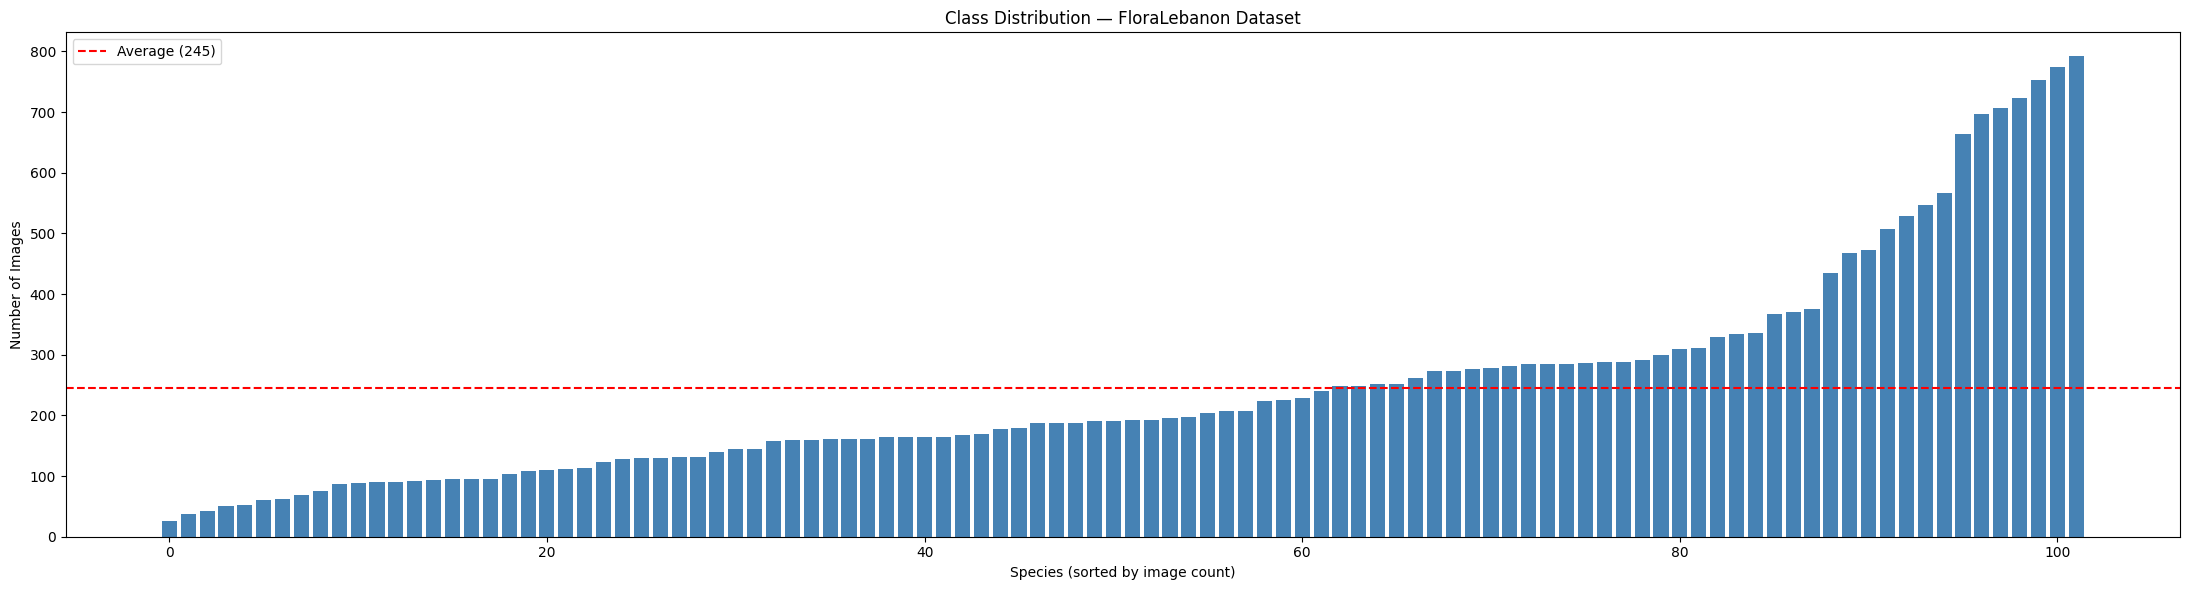

In [3]:
import os
import matplotlib.pyplot as plt

dataset_path ='/kaggle/input/datasets/abidhasanzarif/floral-lebanon-raw-dataset/FloraLebanon_raw_dataset/SLB-SBR_raw_dataset'

# Count images per species
image_counts = {}
for species in sorted(os.listdir(dataset_path)):
    species_path = os.path.join(dataset_path, species)
    if os.path.isdir(species_path):
        count = len([f for f in os.listdir(species_path) 
                     if f.lower().endswith(('.jpg', '.jpeg', '.png'))])
        image_counts[species] = count

# Sort by count
image_counts = dict(sorted(image_counts.items(), key=lambda x: x[1]))

# Statistics
counts = list(image_counts.values())
print(f"Total species: {len(image_counts)}")
print(f"Total images: {sum(counts)}")
print(f"Min images: {min(counts)}")
print(f"Max images: {max(counts)}")
print(f"Average images: {sum(counts)/len(counts):.1f}")

print("\n--- 10 species with LEAST images ---")
for name, count in list(image_counts.items())[:10]:
    print(f"  {count:4d}  {name}")

print("\n--- 10 species with MOST images ---")
for name, count in list(image_counts.items())[-10:]:
    print(f"  {count:4d}  {name}")

# Plot
plt.figure(figsize=(22, 6))
plt.bar(range(len(image_counts)), list(image_counts.values()), color='steelblue')
plt.xlabel("Species (sorted by image count)")
plt.ylabel("Number of Images")
plt.title("Class Distribution — FloraLebanon Dataset")
plt.axhline(y=sum(counts)/len(counts), color='red', 
            linestyle='--', label=f'Average ({sum(counts)/len(counts):.0f})')
plt.legend()
plt.tight_layout()
plt.savefig("class_distribution.png")
plt.show()

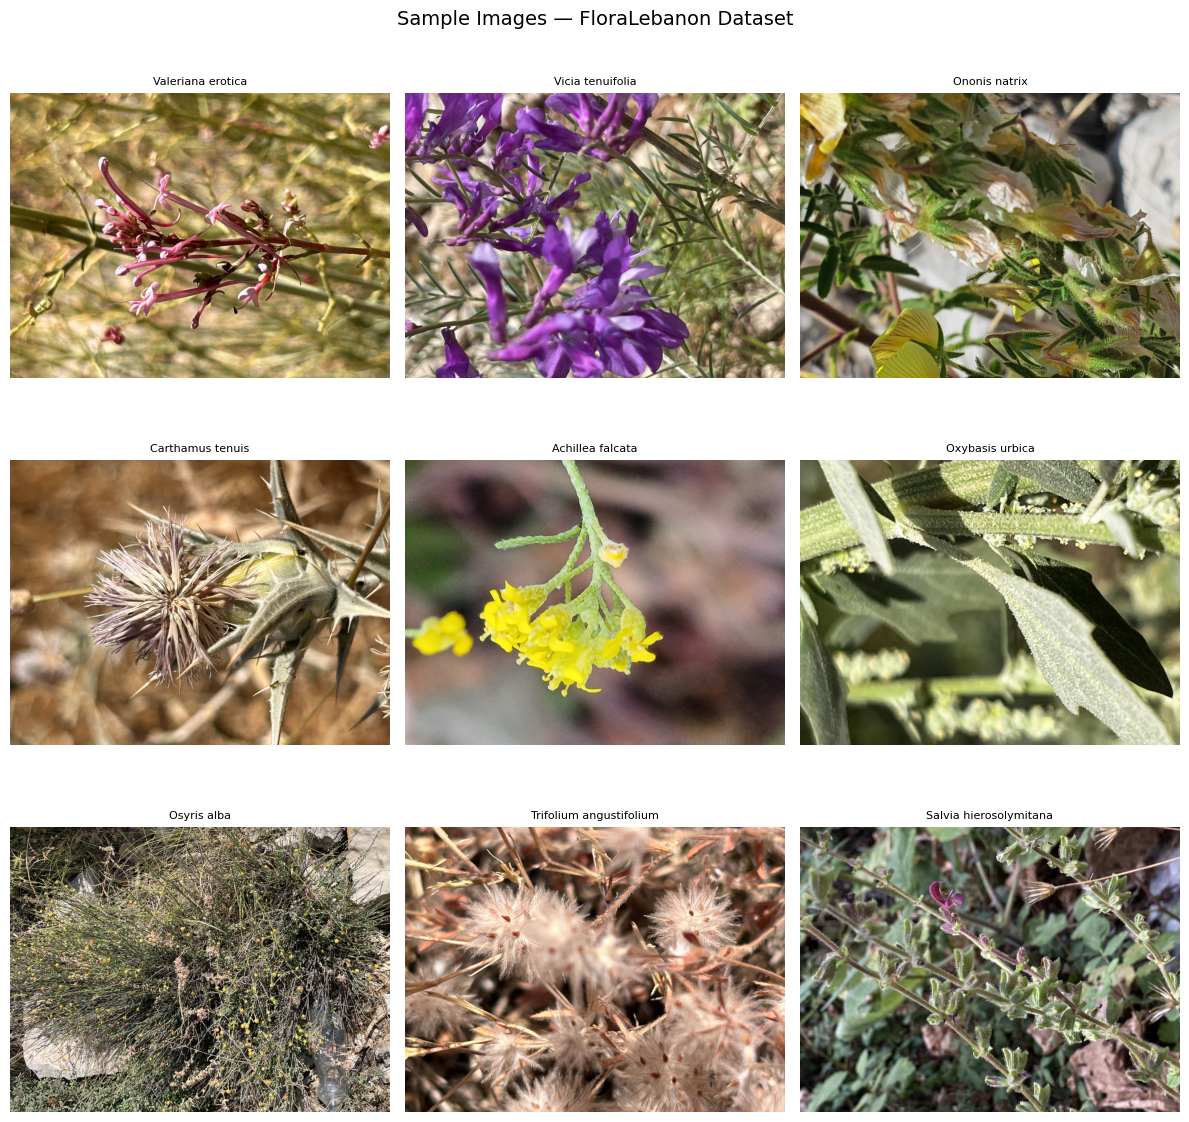

In [4]:
import os
import matplotlib.pyplot as plt
from PIL import Image
import random

dataset_path ='/kaggle/input/datasets/abidhasanzarif/floral-lebanon-raw-dataset/FloraLebanon_raw_dataset/SLB-SBR_raw_dataset'

# Pick 9 random species and show one image from each
species_list = os.listdir(dataset_path)
selected = random.sample(species_list, 9)

fig, axes = plt.subplots(3, 3, figsize=(12, 12))
axes = axes.flatten()

for i, species in enumerate(selected):
    species_path = os.path.join(dataset_path, species)
    images = [f for f in os.listdir(species_path) 
              if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
    
    if images:
        img_path = os.path.join(species_path, random.choice(images))
        img = Image.open(img_path)
        axes[i].imshow(img)
        axes[i].set_title(species[:30], fontsize=8)
        axes[i].axis('off')

plt.suptitle("Sample Images — FloraLebanon Dataset", fontsize=14)
plt.tight_layout()
plt.savefig("sample_images.png")
plt.show()

Total images checked: 24944

Width  — Min: 384, Max: 8160, Avg: 3901
Height — Min: 448, Max: 6120, Avg: 2967


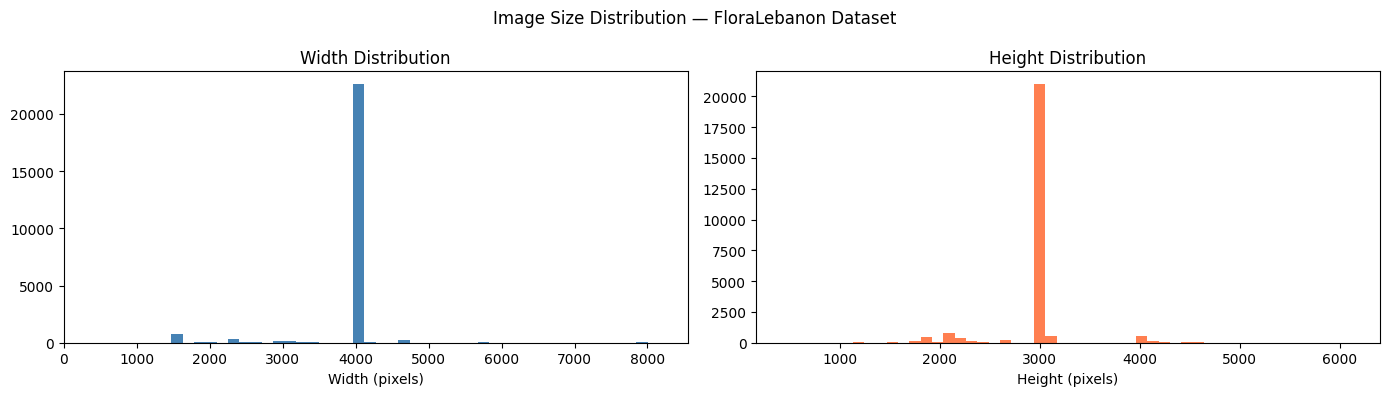

In [5]:
import os
from PIL import Image
import matplotlib.pyplot as plt

dataset_path = '/kaggle/input/datasets/abidhasanzarif/floral-lebanon-raw-dataset/FloraLebanon_raw_dataset/SLB-SBR_raw_dataset'

widths = []
heights = []

for species in os.listdir(dataset_path):
    species_path = os.path.join(dataset_path, species)
    if os.path.isdir(species_path):
        for img_file in os.listdir(species_path):
            if img_file.lower().endswith(('.jpg', '.jpeg', '.png')):
                img_path = os.path.join(species_path, img_file)
                try:
                    with Image.open(img_path) as img:
                        w, h = img.size
                        widths.append(w)
                        heights.append(h)
                except:
                    pass

print(f"Total images checked: {len(widths)}")
print(f"\nWidth  — Min: {min(widths)}, Max: {max(widths)}, Avg: {sum(widths)//len(widths)}")
print(f"Height — Min: {min(heights)}, Max: {max(heights)}, Avg: {sum(heights)//len(heights)}")

# Plot size distribution
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4))
ax1.hist(widths, bins=50, color='steelblue')
ax1.set_title("Width Distribution")
ax1.set_xlabel("Width (pixels)")
ax2.hist(heights, bins=50, color='coral')
ax2.set_title("Height Distribution")
ax2.set_xlabel("Height (pixels)")
plt.suptitle("Image Size Distribution — FloraLebanon Dataset")
plt.tight_layout()
plt.savefig("size_distribution.png")
plt.show()

# Train Test Split

In [6]:
import os
import random
import json

source_path = '/kaggle/input/datasets/abidhasanzarif/floral-lebanon-raw-dataset/FloraLebanon_raw_dataset/SLB-SBR_raw_dataset'

random.seed(42)

TRAIN = 0.70
VAL   = 0.15
TEST  = 0.15

split_data = {'train': {}, 'val': {}, 'test': {}}

for species in sorted(os.listdir(source_path)):
    species_path = os.path.join(source_path, species)
    if not os.path.isdir(species_path):
        continue
    
    images = [os.path.join(species_path, f) 
              for f in os.listdir(species_path)
              if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
    
    random.shuffle(images)
    
    n = len(images)
    n_train = int(n * TRAIN)
    n_val   = int(n * VAL)
    
    split_data['train'][species] = images[:n_train]
    split_data['val'][species]   = images[n_train:n_train + n_val]
    split_data['test'][species]  = images[n_train + n_val:]

# Save split to a small json file
with open('/kaggle/working/splits.json', 'w') as f:
    json.dump(split_data, f)

# Summary
print(f"{'Split':<10} {'Images':>8}")
print("-" * 20)
for split in ['train', 'val', 'test']:
    total = sum(len(v) for v in split_data[split].values())
    print(f"{split:<10} {total:>8}")

print(f"\nSplit file saved to /kaggle/working/splits.json")
print(f"File size: {os.path.getsize('/kaggle/working/splits.json')/1024:.1f} KB")

Split        Images
--------------------
train         17406
val            3695
test           3843

Split file saved to /kaggle/working/splits.json
File size: 3904.5 KB


In [7]:
os.listdir('/kaggle/working')

['size_distribution.png',
 'class_distribution.png',
 'sample_images.png',
 'splits.json',
 '.virtual_documents']

# Data Loder

In [8]:
import json
import torch
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import torchvision.transforms as transforms

# Load splits
with open('/kaggle/working/splits.json', 'r') as f:
    split_data = json.load(f)

# Build label map (species name -> number)
species_names = sorted(split_data['train'].keys())
label_map = {name: idx for idx, name in enumerate(species_names)}

print(f"Number of classes: {len(label_map)}")
print(f"\nFirst 5 labels:")
for name, idx in list(label_map.items())[:5]:
    print(f"  {idx}: {name}")

# Save label map for later use
with open('/kaggle/working/label_map.json', 'w') as f:
    json.dump(label_map, f)

Number of classes: 102

First 5 labels:
  0: Acantholimon libanoticum
  1: Acer hyrcanum subsp. tauricola
  2: Achillea falcata
  3: Achillea kotschyi
  4: Alcea setosa


In [9]:
class FloraDataset(Dataset):
    def __init__(self, split_data, split, label_map, transform=None):
        self.label_map = label_map
        self.transform = transform
        self.samples = []
        
        for species, images in split_data[split].items():
            label = label_map[species]
            for img_path in images:
                self.samples.append((img_path, label))
    
    def __len__(self):
        return len(self.samples)
    
    def __getitem__(self, idx):
        img_path, label = self.samples[idx]
        try:
            img = Image.open(img_path).convert('RGB')
        except:
            # If image is corrupted, return black image
            img = Image.new('RGB', (224, 224), 0)
        if self.transform:
            img = self.transform(img)
        return img, label

# Define transforms
# Train — with augmentation to handle complex backgrounds
train_transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.RandomCrop(224),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.ColorJitter(brightness=0.3, 
                           contrast=0.3, 
                           saturation=0.3),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

# Val and Test — no augmentation, just resize
val_test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

# Create datasets
train_dataset = FloraDataset(split_data, 'train', 
                              label_map, train_transform)
val_dataset   = FloraDataset(split_data, 'val', 
                              label_map, val_test_transform)
test_dataset  = FloraDataset(split_data, 'test', 
                              label_map, val_test_transform)

# Create data loaders
train_loader = DataLoader(train_dataset, batch_size=32, 
                          shuffle=True, num_workers=2)
val_loader   = DataLoader(val_dataset, batch_size=32, 
                          shuffle=False, num_workers=2)
test_loader  = DataLoader(test_dataset, batch_size=32, 
                          shuffle=False, num_workers=2)

print(f"Train samples: {len(train_dataset)}")
print(f"Val samples:   {len(val_dataset)}")
print(f"Test samples:  {len(test_dataset)}")
print(f"\nTrain batches: {len(train_loader)}")
print(f"Val batches:   {len(val_loader)}")

# Quick sanity check — load one batch
images, labels = next(iter(train_loader))
print(f"\nBatch check:")
print(f"  Image tensor shape: {images.shape}")
print(f"  Label tensor shape: {labels.shape}")
print(f"  Image dtype: {images.dtype}")
print(f"  Label range: {labels.min().item()} to {labels.max().item()}")

Train samples: 17406
Val samples:   3695
Test samples:  3843

Train batches: 544
Val batches:   116

Batch check:
  Image tensor shape: torch.Size([32, 3, 224, 224])
  Label tensor shape: torch.Size([32])
  Image dtype: torch.float32
  Label range: 1 to 100


# Model Train

In [10]:
import torch

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device: {device}")

if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")
    print(f"Memory: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")
else:
    print("No GPU found — check accelerator settings")

Device: cuda
GPU: Tesla T4
Memory: 15.6 GB


In [11]:
import torch
import torch.nn as nn
import torchvision.models as models

def build_model(num_classes=102, model_name='efficientnet'):
    if model_name == 'efficientnet':
        model = models.efficientnet_b0(weights='IMAGENET1K_V1')
        # Replace final layer for 102 classes
        model.classifier[1] = nn.Linear(
            model.classifier[1].in_features, num_classes)
    
    elif model_name == 'resnet':
        model = models.resnet50(weights='IMAGENET1K_V1')
        model.fc = nn.Linear(model.fc.in_features, num_classes)
    
    elif model_name == 'mobilenet':
        model = models.mobilenet_v3_small(weights='IMAGENET1K_V1')
        model.classifier[3] = nn.Linear(
            model.classifier[3].in_features, num_classes)
    
    return model

# Build EfficientNet-B0
model = build_model(num_classes=102, model_name='efficientnet')
model = model.to(device)

# Count parameters
total_params = sum(p.numel() for p in model.parameters())
trainable = sum(p.numel() for p in model.parameters() 
                if p.requires_grad)
print(f"Model: EfficientNet-B0")
print(f"Total parameters:     {total_params:,}")
print(f"Trainable parameters: {trainable:,}")
print(f"Model moved to: {device}")

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 124MB/s] 


Model: EfficientNet-B0
Total parameters:     4,138,210
Trainable parameters: 4,138,210
Model moved to: cuda


In [ ]:
import torch.optim as optim
from torch.optim.lr_scheduler import StepLR
import time
import json

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)
scheduler = StepLR(optimizer, step_size=5, gamma=0.5)

def train_one_epoch(model, loader, optimizer, criterion, device):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0
    for batch_idx, (images, labels) in enumerate(loader):
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item()
        _, predicted = outputs.max(1)
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()
        if (batch_idx + 1) % 100 == 0:
            print(f"  Batch {batch_idx+1}/{len(loader)} "
                  f"Loss: {running_loss/(batch_idx+1):.4f} "
                  f"Acc: {100.*correct/total:.2f}%")
    return running_loss/len(loader), 100.*correct/total

def evaluate(model, loader, criterion, device):
    model.eval()
    running_loss = 0.0
    correct = 0
    total = 0
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)
            running_loss += loss.item()
            _, predicted = outputs.max(1)
            total += labels.size(0)
            correct += predicted.eq(labels).sum().item()
    return running_loss/len(loader), 100.*correct/total

# Training loop
EPOCHS = 8
best_val_acc = 0.0
history = {'train_loss': [], 'train_acc': [],
           'val_loss':   [], 'val_acc':   []}

print("Starting training...")
print("="*60)

for epoch in range(EPOCHS):
    start = time.time()
    
    train_loss, train_acc = train_one_epoch(
        model, train_loader, optimizer, criterion, device)
    val_loss, val_acc = evaluate(
        model, val_loader, criterion, device)
    
    scheduler.step()
    
    # Save checkpoint every epoch regardless
    torch.save({
        'epoch': epoch + 1,
        'model_state_dict': model.state_dict(),
        'optimizer_state_dict': optimizer.state_dict(),
        'val_acc': val_acc,
        'history': history
    }, f'/kaggle/working/checkpoint_epoch{epoch+1}.pth')
    
    # Save best model separately
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(model.state_dict(),
                   '/kaggle/working/best_model.pth')
        saved = "✓ best saved"
    else:
        saved = ""
    
    history['train_loss'].append(train_loss)
    history['train_acc'].append(train_acc)
    history['val_loss'].append(val_loss)
    history['val_acc'].append(val_acc)
    
    # Save history after every epoch
    with open('/kaggle/working/history.json', 'w') as f:
        json.dump(history, f)
    
    elapsed = time.time() - start
    print(f"Epoch {epoch+1:2d}/{EPOCHS} | "
          f"Train Loss: {train_loss:.4f} Acc: {train_acc:.2f}% | "
          f"Val Loss: {val_loss:.4f} Acc: {val_acc:.2f}% | "
          f"Time: {elapsed:.0f}s {saved}")

print("="*60)
print(f"Best validation accuracy: {best_val_acc:.2f}%")

Starting training...
  Batch 100/544 Loss: 1.7973 Acc: 53.84%
  Batch 200/544 Loss: 1.5518 Acc: 59.00%
  Batch 300/544 Loss: 1.4236 Acc: 62.10%
  Batch 400/544 Loss: 1.3201 Acc: 64.66%
  Batch 500/544 Loss: 1.2186 Acc: 67.24%
Epoch  1/8 | Train Loss: 1.1933 Acc: 67.80% | Val Loss: 0.6928 Acc: 79.30% | Time: 1990s ✓ best saved
  Batch 100/544 Loss: 0.6549 Acc: 81.16%
  Batch 200/544 Loss: 0.6456 Acc: 81.39%
  Batch 400/544 Loss: 0.6238 Acc: 81.88%
  Batch 500/544 Loss: 0.6204 Acc: 81.84%
Epoch  2/8 | Train Loss: 0.6155 Acc: 82.02% | Val Loss: 0.4892 Acc: 85.98% | Time: 1982s ✓ best saved
  Batch 100/544 Loss: 0.4133 Acc: 87.28%
  Batch 200/544 Loss: 0.4390 Acc: 86.78%
  Batch 300/544 Loss: 0.4395 Acc: 86.81%
  Batch 400/544 Loss: 0.4389 Acc: 86.81%
  Batch 500/544 Loss: 0.4368 Acc: 86.86%
Epoch  3/8 | Train Loss: 0.4378 Acc: 86.72% | Val Loss: 0.3377 Acc: 90.66% | Time: 2004s ✓ best saved
  Batch 100/544 Loss: 0.2949 Acc: 91.03%
  Batch 200/544 Loss: 0.3148 Acc: 90.42%
  Batch 300/544 L

In [2]:
# ============================================
# STEP 1 — Imports
# ============================================
import os, json, torch
import torch.nn as nn
import torchvision.models as models
import torchvision.transforms as transforms
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import numpy as np
from sklearn.metrics import classification_report

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device: {device}")

# ============================================
# STEP 2 — Paths
# ============================================
dataset_path = '/kaggle/input/datasets/abidhasanzarif/floral-lebanon-raw-dataset/FloraLebanon_raw_dataset/SLB-SBR_raw_dataset'

splits_path   = '/kaggle/input/notebooks/abidhasanzarif/florallebanon2/splits.json'
labelmap_path = '/kaggle/input/notebooks/abidhasanzarif/florallebanon2/label_map.json'
model_path    = '/kaggle/input/notebooks/abidhasanzarif/florallebanon2/best_model.pth'

with open(splits_path, 'r') as f:
    split_data = json.load(f)
with open(labelmap_path, 'r') as f:
    label_map = json.load(f)

idx_to_species = {v: k for k, v in label_map.items()}
print(f"Classes: {len(label_map)}")
print(f"Test images: {sum(len(v) for v in split_data['test'].values())}")

# ============================================
# STEP 3 — Dataset class
# ============================================
class FloraDataset(Dataset):
    def __init__(self, split_data, split, label_map, transform=None):
        self.label_map = label_map
        self.transform = transform
        self.samples = []
        for species, images in split_data[split].items():
            label = label_map[species]
            for img_path in images:
                self.samples.append((img_path, label))
    def __len__(self):
        return len(self.samples)
    def __getitem__(self, idx):
        img_path, label = self.samples[idx]
        try:
            img = Image.open(img_path).convert('RGB')
        except:
            img = Image.new('RGB', (224, 224), 0)
        if self.transform:
            img = self.transform(img)
        return img, label

# ============================================
# STEP 4 — Transform and DataLoader
# ============================================
test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

test_dataset = FloraDataset(split_data, 'test',
                             label_map, test_transform)
test_loader  = DataLoader(test_dataset, batch_size=32,
                          shuffle=False, num_workers=4,
                          pin_memory=True)
print(f"Test batches: {len(test_loader)}")

# ============================================
# STEP 5 — Build model and load saved weights
# ============================================
model = models.efficientnet_b0(weights=None)
model.classifier[1] = nn.Linear(
    model.classifier[1].in_features, 102)
model.load_state_dict(torch.load(model_path,
                                  map_location=device))
model = model.to(device)
model.eval()
print("Model loaded — ready for evaluation")

Device: cuda
Classes: 102
Test images: 3843
Test batches: 121
Model loaded — ready for evaluation


In [3]:
# ============================================
# TEST SET EVALUATION
# ============================================
all_preds = []
all_labels = []

print("Running evaluation on test set...")

with torch.no_grad():
    for batch_idx, (images, labels) in enumerate(test_loader):
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        _, predicted = outputs.max(1)
        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())
        if (batch_idx + 1) % 20 == 0:
            print(f"  Batch {batch_idx+1}/{len(test_loader)}")

all_preds  = np.array(all_preds)
all_labels = np.array(all_labels)

# Overall accuracy
correct  = (all_preds == all_labels).sum()
total    = len(all_labels)
test_acc = 100. * correct / total

print(f"\nTest Set Results:")
print(f"{'='*45}")
print(f"Total test images:     {total}")
print(f"Correctly classified:  {correct}")
print(f"Test Accuracy:         {test_acc:.2f}%")

# Per class report
species_names = [idx_to_species[i] for i in range(102)]
report = classification_report(
    all_labels, all_preds,
    target_names=species_names,
    output_dict=True,
    zero_division=0)

print(f"Macro F1-Score:        {report['macro avg']['f1-score']*100:.2f}%")
print(f"Weighted F1-Score:     {report['weighted avg']['f1-score']*100:.2f}%")

# Save report
with open('/kaggle/working/test_report.json', 'w') as f:
    json.dump(report, f)

# Per class F1 scores
per_class = {species_names[i]: {
    'f1': report[species_names[i]]['f1-score'],
    'precision': report[species_names[i]]['precision'],
    'recall': report[species_names[i]]['recall'],
    'support': report[species_names[i]]['support'],
    'train_count': len(split_data['train'][species_names[i]])
} for i in range(102)}

sorted_classes = sorted(per_class.items(), 
                        key=lambda x: x[1]['f1'])

print(f"\n--- 10 WORST performing species ---")
print(f"{'F1':>6} {'Prec':>6} {'Rec':>6} {'Train':>6}  Species")
print("-" * 60)
for name, m in sorted_classes[:10]:
    print(f"{m['f1']*100:>5.1f}% "
          f"{m['precision']*100:>5.1f}% "
          f"{m['recall']*100:>5.1f}% "
          f"{m['train_count']:>6}  {name}")

print(f"\n--- 10 BEST performing species ---")
print(f"{'F1':>6} {'Prec':>6} {'Rec':>6} {'Train':>6}  Species")
print("-" * 60)
for name, m in sorted_classes[-10:]:
    print(f"{m['f1']*100:>5.1f}% "
          f"{m['precision']*100:>5.1f}% "
          f"{m['recall']*100:>5.1f}% "
          f"{m['train_count']:>6}  {name}")

Running evaluation on test set...
  Batch 20/121
  Batch 40/121
  Batch 60/121
  Batch 80/121
  Batch 100/121
  Batch 120/121

Test Set Results:
Total test images:     3843
Correctly classified:  3602
Test Accuracy:         93.73%
Macro F1-Score:        93.34%
Weighted F1-Score:     93.70%

--- 10 WORST performing species ---
    F1   Prec    Rec  Train  Species
------------------------------------------------------------
 78.9%  93.8%  68.2%     97  Sideritis libanotica
 82.4% 100.0%  70.0%     42  Allium rotundum
 82.8%  85.7%  80.0%     64  Achillea falcata
 85.7%  91.3%  80.8%    118  Helichrysum pallasii
 85.7%  92.3%  80.0%     66  Ixiolirion tataricum
 85.7% 100.0%  75.0%    145  Salvia microstegia
 86.1%  83.8%  88.6%    159  Anthemis cretica
 86.2%  80.0%  93.3%    137  Galium incanum
 86.7% 100.0%  76.5%     77  Lapsana communis
 86.7%  83.9%  89.7%    130  Sambucus ebulus

--- 10 BEST performing species ---
    F1   Prec    Rec  Train  Species
-------------------------------

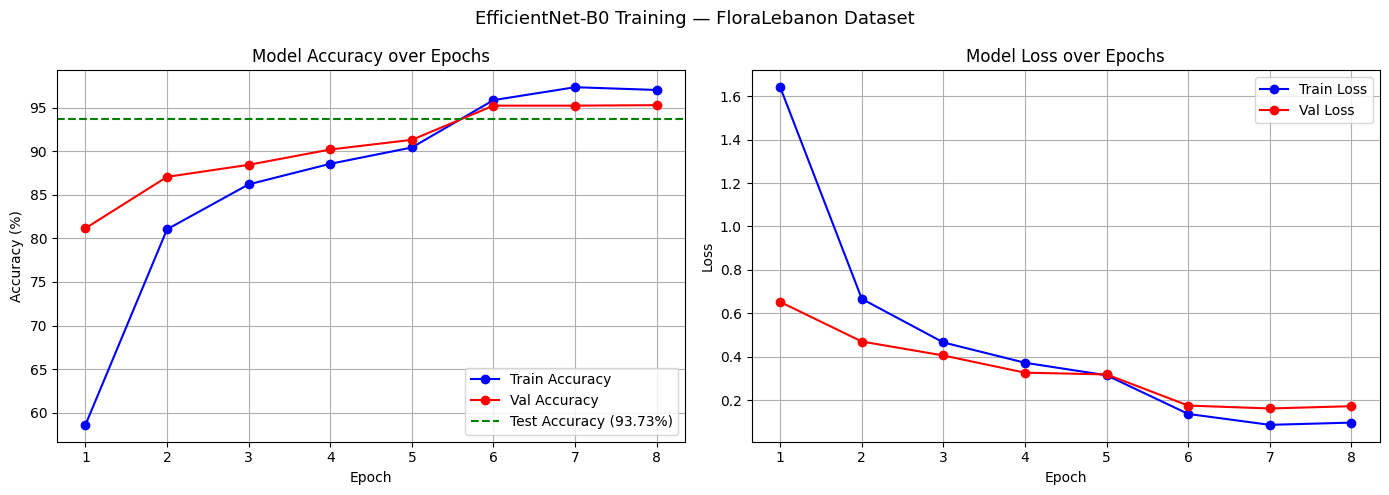

Training curves saved.


In [4]:
import matplotlib.pyplot as plt
import json

# Load history
with open('/kaggle/input/notebooks/abidhasanzarif/florallebanon2/history.json', 'r') as f:
    history = json.load(f)

epochs = range(1, len(history['train_acc']) + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy plot
ax1.plot(epochs, history['train_acc'], 'b-o', 
         label='Train Accuracy')
ax1.plot(epochs, history['val_acc'], 'r-o', 
         label='Val Accuracy')
ax1.axhline(y=93.73, color='green', linestyle='--', 
            label=f'Test Accuracy (93.73%)')
ax1.set_title('Model Accuracy over Epochs')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Accuracy (%)')
ax1.legend()
ax1.grid(True)
ax1.set_xticks(list(epochs))

# Loss plot
ax2.plot(epochs, history['train_loss'], 'b-o', 
         label='Train Loss')
ax2.plot(epochs, history['val_loss'], 'r-o', 
         label='Val Loss')
ax2.set_title('Model Loss over Epochs')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Loss')
ax2.legend()
ax2.grid(True)
ax2.set_xticks(list(epochs))

plt.suptitle('EfficientNet-B0 Training — FloraLebanon Dataset', 
             fontsize=13)
plt.tight_layout()
plt.savefig('/kaggle/working/training_curves.png', 
            dpi=150, bbox_inches='tight')
plt.show()
print("Training curves saved.")